# 模块3：履约与满意度

**业务问题：** 延误对差评的影响有多大？延误出在卖家发货还是物流运输？集中在哪里？结论是否稳健？

**数据：** `dws_order_fulfillment`（96,203 单有效已送达订单，一行一单；建表脚本 `sql/03_dws/01_create_dws_order_fulfillment.sql`）

**口径：** 差评 = 1~2 分；延误 = 送达日晚于承诺日；相关决策 D-023 ~ D-028

**结论：** 详见 `docs/stage_summaries/stage_2.md` 模块3。

In [1]:
from olist_utils import run_query, set_style, COLORS
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

set_style()

run_query("SELECT COUNT(*) AS n FROM dwd_orders")

,n
0,99441


## 3.1 宽表校验

恒等式校验：
检查approve_days seller_days transit_days 三者不为NULL的订单中, 加起来等于delivery_days的比例

In [2]:
sql = """
SELECT SUM(CASE WHEN approve_days + seller_days + transit_days = delivery_days THEN 1 END) AS right_time, 
       AVG(CASE WHEN approve_days + seller_days + transit_days = delivery_days THEN 1 ELSE 0 END) AS rate_right
FROM dws_order_fulfillment
WHERE approve_days IS NOT NULL AND seller_days IS NOT NULL AND transit_days IS NOT NULL
"""
df = run_query(sql)
df

,right_time,rate_right
0,95498.0,1.0


查看订单距离

In [3]:
# 最大订单距离
sql_max_dis = """
SELECT MAX(distance_km) 
FROM dws_order_fulfillment;
"""
run_query(sql_max_dis)

,MAX(distance_km)
0,3399.2


In [4]:
#查询距离超过4500KM的订单数
sql = """
SELECT COUNT(*) AS dis_big_than_4500
FROM dws_order_fulfillment
WHERE distance_km > 4500;
"""
run_query(sql)

,dis_big_than_4500
0,0


## 3.2 延误分段与差评率

分段分析不同延误程度的差评率: 

In [5]:
# 查看各分段差评率
sql_delay = """
SELECT CASE
         WHEN delay_days <= -8 THEN '1 提前8天以上'
         WHEN delay_days <= -1 THEN '2 提前1-7天'
         WHEN delay_days = 0   THEN '3 承诺日当天'
         WHEN delay_days <= 3  THEN '4 晚1-3天'
         WHEN delay_days <= 7  THEN '5 晚4-7天'
         WHEN delay_days <= 14 THEN '6 晚8-14天'
         ELSE '7 晚15天以上'
       END                                  AS delay_group,
       COUNT(*)                             AS orders,
       SUM(has_review)                      AS reviewed,
       SUM(is_bad_review)                   AS bad_reviews,
       AVG(is_bad_review)                   AS bad_rate,
       AVG(review_score)                    AS avg_score,
       AVG(1 - has_review)                  AS no_review_rate,
       AVG(is_review_before_delivery)       AS review_before_delivery_rate
FROM dws_order_fulfillment
GROUP BY delay_group
ORDER BY delay_group
"""
df_delay = run_query(sql_delay)
df_delay

,delay_group,orders,reviewed,bad_reviews,bad_rate,avg_score,no_review_rate,review_before_delivery_rate
0,1 提前8天以上,71046,70673.0,6326.0,0.0895,4.3178,0.0053,0.0022
1,2 提前1-7天,17335,17229.0,1762.0,0.1023,4.2011,0.0061,0.0032
2,3 承诺日当天,1291,1280.0,159.0,0.1242,4.0336,0.0085,0.0063
3,4 晚1-3天,1869,1851.0,595.0,0.3214,3.2907,0.0096,0.2085
4,5 晚4-7天,1802,1748.0,1183.0,0.6768,2.1030,0.0300,0.9068
5,6 晚8-14天,1478,1446.0,1159.0,0.8015,1.6708,0.0217,0.9993
6,7 晚15天以上,1382,1333.0,1044.0,0.7832,1.7247,0.0355,1.0000


In [6]:
#延误与否的整体对比
sql_late = """
SELECT is_late,
       COUNT(*)            AS orders,
       AVG(is_bad_review)  AS bad_rate,
       AVG(review_score)   AS avg_score
FROM dws_order_fulfillment
GROUP BY is_late
"""
df_late = run_query(sql_late)
df_late

,is_late,orders,bad_rate,avg_score
0,0,89672,0.0925,4.2912
1,1,6531,0.6242,2.2706


In [7]:
#差评里有多少延误订单
sql_share = """
SELECT SUM(is_bad_review = 1 AND is_late = 1) / SUM(is_bad_review = 1) AS share_bad_from_late
FROM dws_order_fulfillment
"""
run_query(sql_share)

,share_bad_from_late
0,0.3256


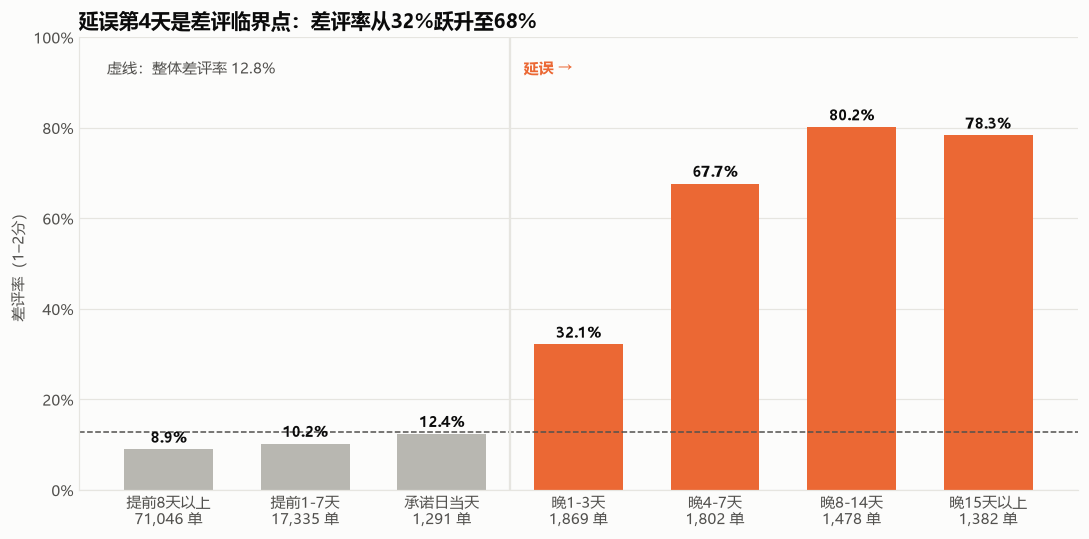

In [8]:
from matplotlib.ticker import FuncFormatter

# 横轴标签：分段名（去掉编号）+ 换行 + 订单数
labels = [f"{g[2:]}\n{n:,} 单" for g, n in zip(df_delay["delay_group"], df_delay["orders"])]
overall = df_delay["bad_reviews"].sum() / df_delay["reviewed"].sum()   # 整体差评率

# 延误的分段（编号 4~7）用橙色，其余用灰色；分段名以编号开头，可直接用字符串比较
colors = [COLORS["orange"] if g >= "4" else COLORS["gray"] for g in df_delay["delay_group"]]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(labels, df_delay["bad_rate"] * 100, color=colors, width=0.65)

# 柱子上方标出差评率
for i, r in enumerate(df_delay["bad_rate"]):
    ax.text(i, r * 100 + 1.5, f"{r:.1%}", ha="center", fontsize=10, fontweight="bold", color=COLORS["text"])

# 参考线：整体差评率
ax.axhline(overall * 100, color=COLORS["text_secondary"], linewidth=1, linestyle="--")
ax.text(-0.45, 92, f"虚线：整体差评率 {overall:.1%}", fontsize=9.5, color=COLORS["text_secondary"])

# 在"未延误"（第 0~2 根柱子）和"延误"（第 3 根起）之间画竖直分隔线
ax.axvline(2.5, color=COLORS["grid"], linewidth=1.5)
ax.text(2.6, 92, "延误 →", fontsize=10, color=COLORS["orange"], fontweight="bold")

ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylabel("差评率（1–2分）")

# 结论标题
ax.set_title("延误第4天是差评临界点：差评率从32%跃升至68%")
fig.tight_layout()
fig.savefig("../docs/figures/m3_delay_bad_review.png", dpi=150, bbox_inches="tight")
plt.show()

> **后续检验（报告阶段）：** "第 4 天临界点"的解释已被推翻。跳升的位置正是评价改为在收货前写的位置（满意度问卷在承诺送达日发出）；只看收货后的评价，晚 1~3 天与晚 4~7 天的差评率差别不显著。见 `s2_report_checks.ipynb` 第 3 节、D-036。

## 3.3 卖家发货 vs 物流运输

当前已经发现延误是导致差评率的重要原因之一，但是我们要细扣到底是 卖家慢 还是 物流慢

分析方法：建立2x2交叉表，列：“最终准时”, “最终延误”；行：“卖家准时”, “卖家延误”

In [9]:
sql = """
SELECT
    is_seller_late,
    is_late,
    COUNT(*)                          AS orders,
    SUM(has_review)                   AS reviewed,
    ROUND(AVG(is_bad_review), 4)      AS bad_rate,
    ROUND(AVG(review_score), 2)       AS avg_score,
    ROUND(AVG(seller_days), 1)        AS avg_seller_days,
    ROUND(AVG(transit_days), 1)       AS avg_transit_days
FROM dws_order_fulfillment
WHERE is_seller_late IS NOT NULL
GROUP BY is_seller_late, is_late
ORDER BY is_seller_late, is_late;
"""
df = run_query(sql)
print(df["orders"].sum())
df

94930


,is_seller_late,is_late,orders,reviewed,bad_rate,avg_score,avg_seller_days,avg_transit_days
0,0,0,81692,81266.0,0.0835,4.33,2.1,8.0
1,0,1,4708,4603.0,0.6213,2.27,2.4,31.6
2,1,0,6721,6670.0,0.1321,4.09,7.9,7.7
3,1,1,1809,1762.0,0.6311,2.27,13.2,18.3


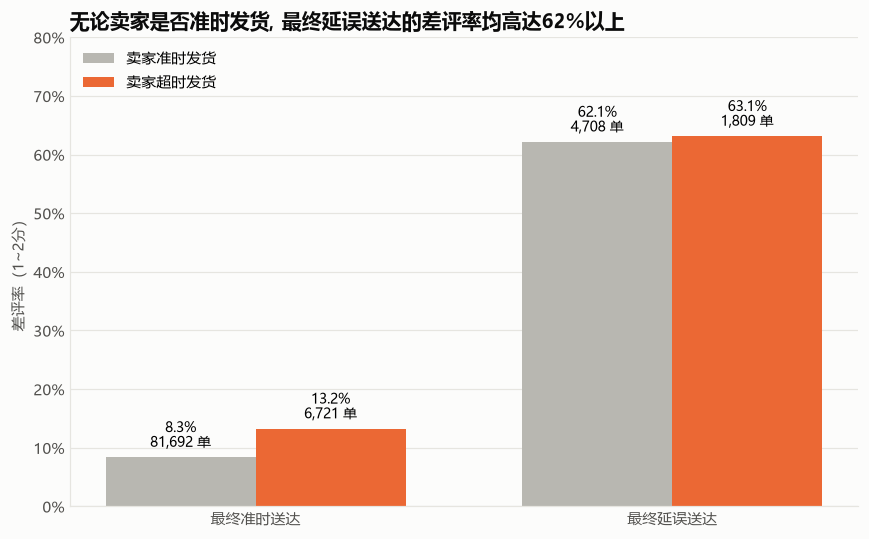

In [10]:
import numpy as np
import matplotlib.ticker as mticker

pv   = df.pivot(index="is_late", columns="is_seller_late", values="bad_rate")
pv_n = df.pivot(index="is_late", columns="is_seller_late", values="orders")

x = np.arange(len(pv.index))
w = 0.36
fig, ax = plt.subplots(figsize=(8, 5))

for i, (col, label, color) in enumerate([
        (0, "卖家准时发货", COLORS["gray"]),
        (1, "卖家超时发货", COLORS["orange"])]):
    bars = ax.bar(x + (i - 0.5) * w, pv[col], width=w, color=color, label=label)
    for b, n in zip(bars, pv_n[col]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012,
                f"{b.get_height():.1%}\n{n:,} 单", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(["最终准时送达", "最终延误送达"])
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylabel("差评率（1~2分）")
ax.legend(frameon=False, loc="upper left")
ax.set_title("无论卖家是否准时发货, 最终延误送达的差评率均高达62%以上", loc="left")

fig.tight_layout()
fig.savefig("../docs/figures/m3_seller_vs_logistics.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.4 跨州与各州履约

查看跨州订单是否更容易延误、差评更多。分两层看：跨州 vs 同州; 按买家所在州拆开看具体哪些州有问题。

In [11]:
#跨州vs同州
sql_k_vs_t = """
SELECT
    is_cross_state,
    COUNT(*)                                   AS orders,
    ROUND(AVG(is_late), 4)                     AS late_rate,
    ROUND(AVG(is_bad_review), 4)               AS bad_rate,
    ROUND(AVG(delivery_days), 1)               AS avg_delivery_days,
    ROUND(AVG(delivery_days - delay_days), 1)  AS avg_promise_days
FROM dws_order_fulfillment
WHERE is_cross_state IS NOT NULL
GROUP BY is_cross_state;
"""
df_k_vs_t = run_query(sql_k_vs_t)
df_k_vs_t

,is_cross_state,orders,late_rate,bad_rate,avg_delivery_days,avg_promise_days
0,1,60782,0.0816,0.1366,15.1,27.7
1,0,34149,0.0457,0.0998,7.9,18.1


In [12]:
#按买家州
sql_m = """
SELECT
    customer_state,
    COUNT(*)                                   AS orders,
    ROUND(AVG(is_late), 4)                     AS late_rate,
    ROUND(AVG(is_bad_review), 4)               AS bad_rate,
    ROUND(AVG(delivery_days), 1)               AS avg_delivery_days,
    ROUND(AVG(delivery_days - delay_days), 1)  AS avg_promise_days
FROM dws_order_fulfillment
GROUP BY customer_state
ORDER BY late_rate DESC;
"""
df_m = run_query(sql_m)
df_m

,customer_state,orders,late_rate,bad_rate,avg_delivery_days,avg_promise_days
0,AL,396,0.2146,0.2137,24.5,33.1
1,MA,713,0.1753,0.2003,21.5,30.9
2,SE,332,0.1536,0.1903,21.4,31.2
3,PI,475,0.1389,0.1617,19.4,30.6
4,CE,1273,0.1383,0.1721,21.2,31.8
5,RR,40,0.1250,0.1500,29.9,46.1
6,BA,3253,0.1217,0.1702,19.3,30.0
7,RJ,12310,0.1214,0.1833,15.2,26.9
8,PA,942,0.1125,0.1798,23.7,37.7
9,ES,1992,0.1074,0.1384,15.7,26.2


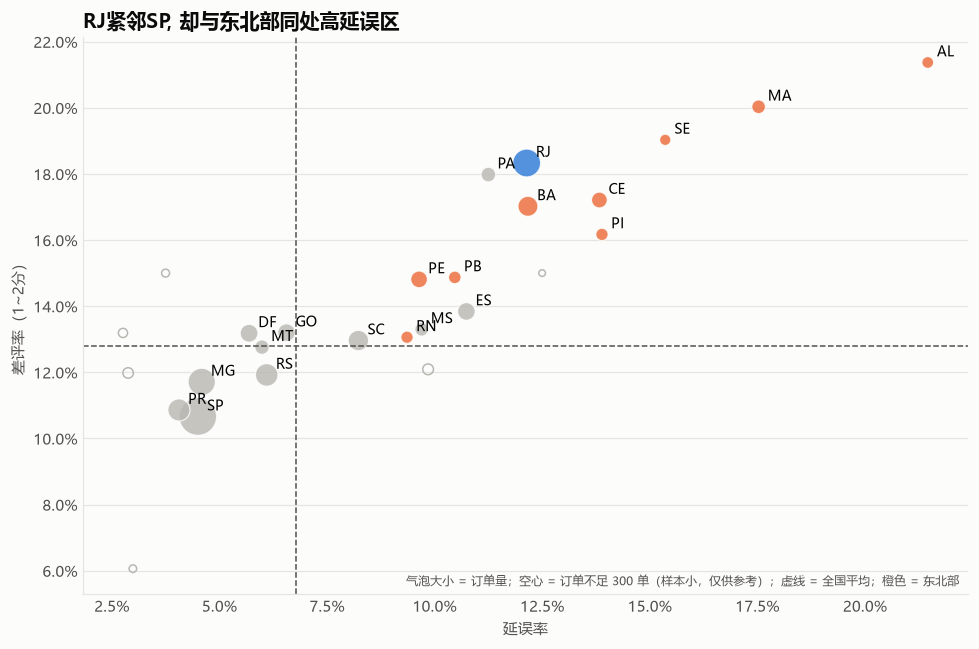

In [13]:
import numpy as np
import matplotlib.ticker as mticker

df_state = run_query(sql_m)

MIN_N = 300
NORDESTE = ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]
big   = df_state[df_state["orders"] >= MIN_N]
small = df_state[df_state["orders"] <  MIN_N]
size  = lambda n: np.sqrt(n) * 3          # 面积按订单量的平方根缩放，避免 SP 一个点占满全图

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(small["late_rate"], small["bad_rate"], s=size(small["orders"]),
           facecolors="none", edgecolors=COLORS["gray"], linewidths=1)

colors = [COLORS["orange"] if s in NORDESTE
          else (COLORS["blue"] if s == "RJ" else COLORS["gray"])
          for s in big["customer_state"]]
ax.scatter(big["late_rate"], big["bad_rate"], s=size(big["orders"]),
           c=colors, alpha=0.8, edgecolors="white", linewidths=0.8)

for _, r in big.iterrows():
    ax.annotate(r["customer_state"], (r["late_rate"], r["bad_rate"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9)

ax.axvline(0.0679, color=COLORS["text_secondary"], linestyle="--", linewidth=1)
ax.axhline(0.1280, color=COLORS["text_secondary"], linestyle="--", linewidth=1)

ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("延误率")
ax.set_ylabel("差评率（1~2分）")
ax.set_title("RJ紧邻SP, 却与东北部同处高延误区", loc="left")
ax.text(0.99, 0.01,
        f"气泡大小 = 订单量；空心 = 订单不足 {MIN_N} 单（样本小，仅供参考）；虚线 = 全国平均；橙色 = 东北部",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=COLORS["text_secondary"])

fig.tight_layout()
fig.savefig("../docs/figures/m3_state_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.5 敏感性分析与显著性检验

敏感性分析：

In [14]:
#S1：主口径: 多次评价取最后一次(D-013), 替代口径：取第一次评价
sql_1 = """
SELECT is_late,
       COUNT(*)                              AS orders,
       ROUND(AVG(is_bad_review), 4)          AS bad_rate_main,
       ROUND(AVG(first_review_score <= 2), 4) AS bad_rate_first
FROM dws_order_fulfillment
GROUP BY is_late;
"""
df_1 = run_query(sql_1)
df_1

,is_late,orders,bad_rate_main,bad_rate_first
0,0,89672,0.0925,0.0924
1,1,6531,0.6242,0.6235


In [15]:
#S2：主口径: 时间戳异常的订单保留(D-014), 替代口径: 剔除时间戳异常订单
sql_2 = """
SELECT is_late,
       COUNT(*)                     AS orders,
       ROUND(AVG(is_bad_review), 4) AS bad_rate
FROM dws_order_fulfillment
WHERE has_ts_anomaly = 0
GROUP BY is_late;
"""
df_2 = run_query(sql_2)
df_2

,is_late,orders,bad_rate
0,0,88327,0.0924
1,1,6507,0.6248


In [16]:
#S3：主口径: 跨州只算单卖家订单, 替代口径: 多卖家订单按GMV最大卖家归属
sql_3 = """
SELECT is_cross_state_top,
       COUNT(*)                     AS orders,
       ROUND(AVG(is_late), 4)       AS late_rate,
       ROUND(AVG(is_bad_review), 4) AS bad_rate
FROM dws_order_fulfillment
GROUP BY is_cross_state_top;
"""
df_3 = run_query(sql_3)
df_3

,is_cross_state_top,orders,late_rate,bad_rate
0,1,61593,0.0807,0.1411
1,0,34610,0.0451,0.1046


In [17]:
#S4：主口径: 包含收货前填写的评价(D-021), 替代口径: 排除收货前填写的评价
sql_4 = """
SELECT is_late,
       COUNT(*)                                                          AS orders,
       SUM(has_review)                                                   AS reviewed,
       SUM(is_review_before_delivery)                                    AS n_review_before_delivery,
       ROUND(AVG(is_bad_review), 4)                                      AS bad_rate_main,
       ROUND(AVG(CASE WHEN is_review_before_delivery = 0 THEN is_bad_review END), 4) AS bad_rate_excl
FROM dws_order_fulfillment
GROUP BY is_late;
"""
df_4 = run_query(sql_4)
df_4

,is_late,orders,reviewed,n_review_before_delivery,bad_rate_main,bad_rate_excl
0,0,89672,89182.0,221.0,0.0925,0.0923
1,1,6531,6378.0,4749.0,0.6242,0.2511


S4 解读：延误订单的评价中约 74% 写于收货之前。排除这些评价后，延误订单差评率从 62.4% 降至 25.1%，倍数从 6.8 倍降至 2.7 倍。
收货前的评价本身就是买家对"等不到货"的反应，排除它们等于排除了延误效应的主要部分，因此主口径保留这些评价。
结论：延误导致差评的**方向**在所有口径下都成立；**效应大小**取决于是否计入收货前的评价（2.7~6.8 倍）。

显著性实验: 检验2x2图中(2)组[卖家准时、最终延误]差评率62.1% 和 (4)组[卖家超时、最终延误]63.1%, 差了 1 个百分点; 判断这 1 个点是真实差别，还是碰巧？

In [18]:
sql = """
SELECT is_seller_late, is_late,
       SUM(has_review)    AS reviewed,
       SUM(is_bad_review) AS bad
FROM dws_order_fulfillment
WHERE is_seller_late IS NOT NULL
GROUP BY is_seller_late, is_late;
"""
df = run_query(sql)
df

,is_seller_late,is_late,reviewed,bad
0,1,0,6670.0,881.0
1,0,0,81266.0,6782.0
2,0,1,4603.0,2860.0
3,1,1,1762.0,1112.0


In [19]:
import math
from scipy.stats import norm

cnt = run_query(sql)
cnt["reviewed"] = cnt["reviewed"].astype(int)
cnt["bad"]      = cnt["bad"].astype(int)
cnt["bad_rate"] = cnt["bad"] / cnt["reviewed"]
g = cnt.set_index(["is_seller_late", "is_late"])   # 用 (卖家是否超时, 是否延误) 作为行的"名字"
print(g)                                             # 核对：bad_rate 要和 3.3 的表一致

def grp(seller_late, late):
    r = g.loc[(seller_late, late)]
    return int(r["bad"]), int(r["reviewed"])

def two_prop_ztest(bad1, n1, bad2, n2):
    p1, p2 = bad1 / n1, bad2 / n2
    p_pool = (bad1 + bad2) / (n1 + n2)                       # 假设两组相同时的共同差评率
    se = math.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))    # 差值的标准误
    z = (p2 - p1) / se                                       # 差距是标准误的几倍
    p_value = 2 * (1 - norm.cdf(abs(z)))                     # 双侧检验
    return round(p2 - p1, 4), round(z, 2), p_value

b1, n1 = grp(0, 0)   # ①
b2, n2 = grp(0, 1)   # ②
b3, n3 = grp(1, 0)   # ③
b4, n4 = grp(1, 1)   # ④

print("② vs ④:", two_prop_ztest(b2, n2, b4, n4))
print("① vs ③:", two_prop_ztest(b1, n1, b3, n3))

                        reviewed   bad  bad_rate
is_seller_late is_late                          
1              0            6670   881  0.132084
0              0           81266  6782  0.083454
               1            4603  2860  0.621334
1              1            1762  1112  0.631101
② vs ④: (0.0098, 0.72, np.float64(0.4716472651986181))
① vs ③: (0.0486, 13.54, np.float64(0.0))


## 3.6 延误的时间分布

前面的分析把 20 个月合在一起。这里按月拆开，检查延误是常态还是集中在少数时期。高峰月定义为月度延误率超过 10% 的月份（D-032）。

In [20]:
# 按月看延误率和差评率
sql_month = """
SELECT purchase_month,
       COUNT(*)                     AS orders,
       SUM(is_late)                 AS late_orders,
       ROUND(AVG(is_late), 4)       AS late_rate,
       ROUND(AVG(is_bad_review), 4) AS bad_rate
FROM dws_order_fulfillment
GROUP BY purchase_month
ORDER BY purchase_month
"""
df_month = run_query(sql_month)
df_month[["late_rate", "bad_rate"]] = df_month[["late_rate", "bad_rate"]].astype(float)

# 高峰月：延误率超过 10% 的月份（D-032）
SPIKE_THRESHOLD = 0.10
spike_months = df_month.loc[df_month["late_rate"] > SPIKE_THRESHOLD, "purchase_month"].tolist()
print("高峰月：", spike_months)
print(f"高峰月订单占比：{df_month.loc[df_month['purchase_month'].isin(spike_months), 'orders'].sum() / df_month['orders'].sum():.1%}")
print(f"高峰月延误订单占比：{df_month.loc[df_month['purchase_month'].isin(spike_months), 'late_orders'].sum() / df_month['late_orders'].sum():.1%}")
df_month

高峰月： ['2017-11', '2018-02', '2018-03']
高峰月订单占比：21.7%
高峰月延误订单占比：48.4%


,purchase_month,orders,late_orders,late_rate,bad_rate
0,2017-01,750,22.0,0.0293,0.1201
1,2017-02,1653,49.0,0.0296,0.1108
2,2017-03,2546,116.0,0.0456,0.1124
3,2017-04,2303,151.0,0.0656,0.1293
4,2017-05,3545,106.0,0.0299,0.1007
5,2017-06,3135,95.0,0.0303,0.1074
6,2017-07,3872,108.0,0.0279,0.0994
7,2017-08,4193,122.0,0.0291,0.0939
8,2017-09,4150,182.0,0.0439,0.1027
9,2017-10,4478,187.0,0.0418,0.1107


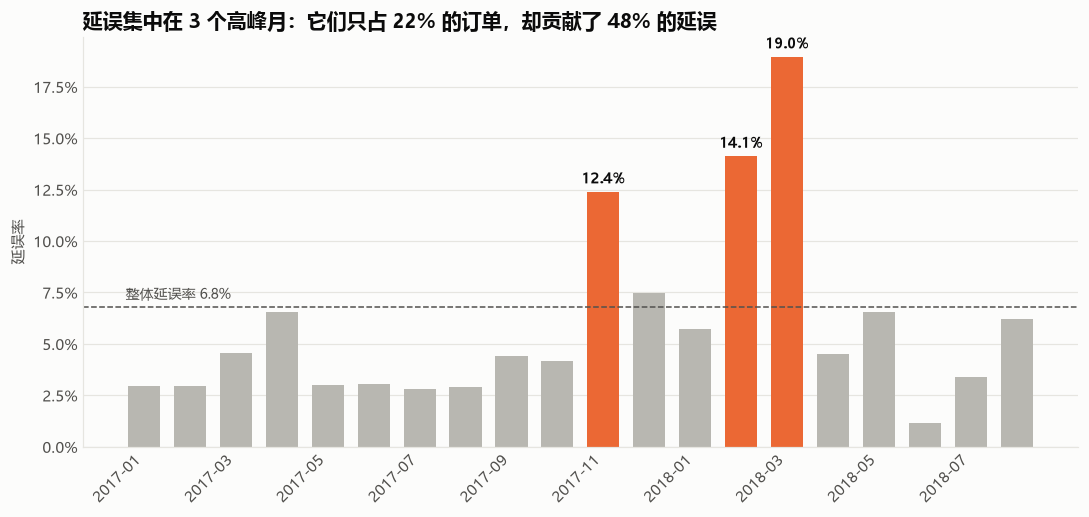

In [21]:
# 月度延误率：高峰月用橙色突出
import matplotlib.ticker as mticker

overall_late = df_month["late_orders"].sum() / df_month["orders"].sum()
colors = [COLORS["orange"] if m in spike_months else COLORS["gray"] for m in df_month["purchase_month"]]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(df_month["purchase_month"], df_month["late_rate"], color=colors, width=0.7)
for i, (m, r) in enumerate(zip(df_month["purchase_month"], df_month["late_rate"])):
    if m in spike_months:
        ax.text(i, r + 0.004, f"{r:.1%}", ha="center", fontsize=9, fontweight="bold", color=COLORS["text"])
ax.axhline(overall_late, color=COLORS["text_secondary"], linestyle="--", linewidth=1)
ax.text(-0.4, overall_late + 0.004, f"整体延误率 {overall_late:.1%}", fontsize=9, color=COLORS["text_secondary"])
ax.set_xticks(range(0, len(df_month), 2))
ax.set_xticklabels(df_month["purchase_month"][::2], rotation=45, ha="right")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylabel("延误率")
ax.set_title("延误集中在 3 个高峰月：它们只占 22% 的订单，却贡献了 48% 的延误")
fig.tight_layout()
fig.savefig("../docs/figures/m3_monthly_delay.png", dpi=150, bbox_inches="tight")
plt.show()

**读图：** 3 个高峰月（2017-11、2018-02、2018-03）只占约 22% 的订单，却贡献了约 48% 的延误订单。下面检查前面的结论在平常月和高峰月是否都成立。

In [22]:
# 高峰月 vs 平常月：延误对差评的影响是否在两种时期都成立
spike_list = ", ".join(f"'{m}'" for m in spike_months)
sql_period = f"""
SELECT CASE WHEN purchase_month IN ({spike_list}) THEN '高峰月' ELSE '平常月' END AS period,
       is_late,
       COUNT(*)                     AS orders,
       ROUND(AVG(is_bad_review), 4) AS bad_rate
FROM dws_order_fulfillment
GROUP BY period, is_late
ORDER BY period, is_late
"""
run_query(sql_period)

,period,is_late,orders,bad_rate
0,平常月,0,71984,0.0898
1,平常月,1,3373,0.5690
2,高峰月,0,17688,0.1033
3,高峰月,1,3158,0.6827


In [23]:
# 跨州效应在两种时期分别有多大
sql_cross = f"""
SELECT CASE WHEN purchase_month IN ({spike_list}) THEN '高峰月' ELSE '平常月' END AS period,
       is_cross_state,
       COUNT(*)               AS orders,
       ROUND(AVG(is_late), 4) AS late_rate
FROM dws_order_fulfillment
WHERE is_cross_state IS NOT NULL
GROUP BY period, is_cross_state
ORDER BY period, is_cross_state
"""
df_cross = run_query(sql_cross)
df_cross["late_rate"] = df_cross["late_rate"].astype(float)
pv = df_cross.pivot(index="period", columns="is_cross_state", values="late_rate")
pv["跨州/同州"] = (pv[1] / pv[0]).round(2)
pv

is_cross_state,0,1,跨州/同州
period,,,
平常月,0.0378,0.0496,1.31
高峰月,0.0756,0.1933,2.56


In [24]:
# RJ 与邻近州在两种时期的延误率，以及 RJ 在平常月的延误占比
sql_rj = f"""
SELECT customer_state,
       CASE WHEN purchase_month IN ({spike_list}) THEN '高峰月' ELSE '平常月' END AS period,
       COUNT(*)               AS orders,
       ROUND(AVG(is_late), 4) AS late_rate
FROM dws_order_fulfillment
WHERE customer_state IN ('RJ', 'SP', 'MG')
GROUP BY customer_state, period
ORDER BY customer_state, period
"""
print(run_query(sql_rj))

sql_rj_share = f"""
SELECT ROUND(SUM(CASE WHEN customer_state = 'RJ' THEN is_late END) / SUM(is_late), 4) AS rj_share_all,
       ROUND(SUM(CASE WHEN customer_state = 'RJ' AND purchase_month NOT IN ({spike_list}) THEN is_late END)
             / SUM(CASE WHEN purchase_month NOT IN ({spike_list}) THEN is_late END), 4)  AS rj_share_normal
FROM dws_order_fulfillment
"""
run_query(sql_rj_share)

  customer_state period  orders  late_rate
0             MG    平常月    8751     0.0242
1             MG    高峰月    2568     0.1195
2             RJ    平常月    9555     0.0665
3             RJ    高峰月    2755     0.3122
4             SP    平常月   31898     0.0358
5             SP    高峰月    8501     0.0794


,rj_share_all,rj_share_normal
0,0.2289,0.1883


**结论：**
- 延误对差评的影响在两种时期都成立：平常月延误订单差评率 56.9%（未延误 9.0%），高峰月 68.3%（未延误 10.3%）
- **跨州效应主要出现在高峰月**：平常月跨州订单延误率只是同州的 1.3 倍，高峰月是 2.6 倍。合并计算的 1.8 倍主要由高峰月造成
- **RJ 的问题在平常月也存在，但被高峰月放大**：平常月 RJ 延误率 6.6%，约为 SP 的 1.9 倍、MG 的 2.7 倍；高峰月达 31%。RJ 占全部延误的 23%，只看平常月为 19%

> **后续检验（报告阶段）：** 3 个"高峰月"中，2018-02、2018-03 的订单量都低于 2018-01，已改称"高延误月"（D-035）。这几个月是物流运输变慢、而承诺天数没有跟着放宽，缓冲被压缩。见 `s2_report_checks.ipynb` 第 4 节。

## 3.7 多件订单与差评

3.2 发现延误只能解释约三分之一的差评。这里检查另一个可能的因素：一笔订单包含多件商品。只比较准时送达的订单，以排除延误的影响。

In [25]:
# 订单类型：单件 / 多件同一卖家 / 多件多个卖家
sql_items = """
SELECT CASE WHEN n_items = 1         THEN '1 单件'
            WHEN is_multi_seller = 0 THEN '2 多件、同一卖家'
            ELSE                          '3 多件、多个卖家' END AS item_type,
       is_late,
       COUNT(*)                     AS orders,
       SUM(has_review)              AS reviewed,
       SUM(is_bad_review)           AS bad_reviews,
       ROUND(AVG(is_bad_review), 4) AS bad_rate
FROM dws_order_fulfillment
GROUP BY item_type, is_late
ORDER BY item_type, is_late
"""
df_items = run_query(sql_items)
df_items[["reviewed", "bad_reviews"]] = df_items[["reviewed", "bad_reviews"]].astype(int)
df_items

,item_type,is_late,orders,reviewed,bad_reviews,bad_rate
0,1 单件,0,80576,80174,6034,0.0753
1,1 单件,1,6022,5887,3656,0.6210
2,2 多件、同一卖家,0,7837,7762,1629,0.2099
3,2 多件、同一卖家,1,496,479,316,0.6597
4,3 多件、多个卖家,0,1259,1246,584,0.4687
5,3 多件、多个卖家,1,13,12,9,0.7500


In [26]:
# 统一口径比较：延误与多件订单各自造成了多少"超额差评"
# 超额差评 = 该组有评价订单数 × (该组差评率 − 基准组差评率)
g = df_items.groupby("is_late")[["reviewed", "bad_reviews"]].sum()
bad_ontime = g.loc[0, "bad_reviews"] / g.loc[0, "reviewed"]
bad_late   = g.loc[1, "bad_reviews"] / g.loc[1, "reviewed"]
excess_delay = g.loc[1, "reviewed"] * (bad_late - bad_ontime)              # 基准：未延误订单

ontime = df_items[df_items["is_late"] == 0].set_index("item_type")
single_rate = ontime.loc["1 单件", "bad_reviews"] / ontime.loc["1 单件", "reviewed"]
multi = ontime.drop(index="1 单件")
excess_multi = (multi["bad_reviews"] - multi["reviewed"] * single_rate).sum()   # 基准：准时的单件订单

total_bad = df_items["bad_reviews"].sum()
print(f"全部差评：{total_bad:,}")
print(f"延误造成的超额差评：  {excess_delay:,.0f}（{excess_delay / total_bad:.1%}）")
print(f"多件订单造成的超额差评：{excess_multi:,.0f}（{excess_multi / total_bad:.1%}）")

全部差评：12,228
延误造成的超额差评：  3,391（27.7%）
多件订单造成的超额差评：1,535（12.6%）


In [27]:
# 显著性检验：准时送达的订单中，单件 vs 多件同一卖家（two_prop_ztest 已在 3.5 定义）
a, b = ontime.loc["1 单件"], ontime.loc["2 多件、同一卖家"]
print("准时订单 单件 vs 多件同一卖家：", two_prop_ztest(a["bad_reviews"], a["reviewed"], b["bad_reviews"], b["reviewed"]))

准时订单 单件 vs 多件同一卖家： (np.float64(0.1346), np.float64(40.15), np.float64(0.0))


**结论：**
- 准时送达的订单中，单件订单差评率 7.5%，多件同一卖家 21.0%，多件多个卖家 46.9%；单件与多件同一卖家的差异显著（p < 0.001）
- 按统一口径（超额差评）比较：延误约造成 3,390 条（占全部差评 27.7%），多件订单约 1,535 条（12.6%）。延误是已识别的最大差评来源，多件订单其次
- 多件订单差评率高的原因（分开发货、只收到部分商品、缺件等）现有数据无法确认，需要分析评论文本或与客服数据核对

> **后续检验（报告阶段）：** 评论文本显示，准时送达的多件订单差评评论中约六成在说缺件或只收到部分商品。见 `s2_report_checks.ipynb` 第 5 节、D-038。